# Supply-Chain Late-Delivery Risk Model

**NextGen Institute · Machine Learning final project**

This notebook builds a model that predicts, **before an order ships**, whether it will arrive late, using the DataCo Smart Supply Chain dataset from Kaggle. It is written to run top to bottom: choose **Restart, then Run All**.

> **Runtime:** about 15 to 20 minutes, almost all of it in the model comparison (section 10) and tuning (section 11). To skip the tuning search, set `RUN_TUNING = False` in the setup cell. The notebook then uses the best settings that the search found.

## Contents
1. Problem framing
2. Setup
3. Data loading and understanding
4. Leakage audit
5. Building the feature table
6. Train/test split (by order)
7. Exploratory data analysis (training data only)
8. Feature reduction
9. Preprocessing pipelines
10. Model comparison (cross-validation)
11. Hyperparameter tuning
12. Final model
13. Choosing the decision cutoff (training data only)
14. Final evaluation on the test set
15. Business insight and limitations
16. Saving the model for the app

## 1. Problem framing

- **Who has the problem:** The logistics and operations team of a global distributor that ships orders across many markets using different shipping modes. Late deliveries hurt customer satisfaction and cost the company money.
- **Decision the model supports:** Before an order ships, the team decides whether to warn the customer or review the order. The model scores each order's risk of being late using only information known at that moment.
- **Target variable:** `Late_delivery_risk` (1 = late, 0 = on time)
- **Metric that matters and why:** Recall for the late class matters because a missed late order (a false negative) means an unhappy customer and no chance to act, while a false alarm only costs an unnecessary warning. Precision, F1 and ROC-AUC are reported alongside it, because a model that flags every order gets perfect recall and is useless. Accuracy alone would be misleading, so it is not the main metric.

## 2. Setup

Libraries, a fixed random seed for reproducibility, and the settings used later in the notebook.

In [ ]:
%matplotlib inline
import os
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GroupShuffleSplit, RandomizedSearchCV, StratifiedGroupKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ---- settings ----
RANDOM_STATE = 42
TEST_SIZE = 0.20
DATA_PATH = "data/DataCoSupplyChainDataset.csv"
RUN_TUNING = True   

pd.options.display.max_columns = 60

## 3. Data loading and understanding

The file uses `latin-1` encoding. Each row is one **item** of an order, so one order can span several rows. This matters later for the train/test split.

In [2]:
df = pd.read_csv(DATA_PATH, encoding="latin-1")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,EE. UU.,XXXXXXXXX,Tana,19490,Tate,XXXXXXXXX,Home Office,CA,3200 Amber Bend,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,1/13/2018 11:45,75937,1360,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Orli,19489,Hendricks,XXXXXXXXX,Corporate,PR,8671 Iron Anchor Corners,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,1/13/2018 11:24,75936,1360,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


**Size, structure, class balance and missing values.**

In [3]:
n_orders = df["Order Id"].nunique()
print(f"Unique orders: {n_orders:,} | average rows per order: {len(df) / n_orders:.2f}")
print("\nColumn types:")
print(df.dtypes.value_counts().to_string())

print("\nTarget balance (Late_delivery_risk):")
print(df["Late_delivery_risk"].value_counts(normalize=True).round(3).to_string())

missing = df.isna().sum()
print("\nColumns with missing values:")
print(missing[missing > 0].to_string())

Unique orders: 65,752 | average rows per order: 2.75

Column types:
str        24
float64    15
int64      14

Target balance (Late_delivery_risk):
Late_delivery_risk
1    0.548
0    0.452

Columns with missing values:
Customer Lname              8
Customer Zipcode            3
Order Zipcode          155679
Product Description    180519


**What this shows**
- 180,519 rows and 53 columns, but only 65,752 distinct orders (about 2.7 rows per order).
- The classes are fairly balanced: about 54.8% of rows are late, so this is not a heavy-imbalance problem.
- Almost nothing is missing, except two columns that are unusable: `Order Zipcode` (about 86% missing) and `Product Description` (completely empty).

## 4. Leakage audit

The model must predict **before the order ships**, so it may only use information that is known when the order is placed. Several columns are known only afterwards. A model that uses them looks perfect but is useless in practice. Each test below checks one suspicious column.

**Test 1: `Delivery Status`.** Compare it with the target.

In [4]:
pd.crosstab(df["Delivery Status"], df["Late_delivery_risk"])

Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


Every "Late delivery" row is late, and every other status is not late. `Delivery Status` is the target in disguise.

**Test 2: actual shipping days.** Compare real and scheduled days with the target.

In [5]:
gap = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
print(pd.crosstab(gap > 0, df["Late_delivery_risk"], rownames=["real days > scheduled days"]))

rule_accuracy = ((gap > 0).astype(int) == df["Late_delivery_risk"]).mean()
print(f"\nAccuracy of the rule 'late if real days > scheduled days': {rule_accuracy:.3f}")

Late_delivery_risk              0      1
real days > scheduled days              
False                       77119      0
True                         4423  98977

Accuracy of the rule 'late if real days > scheduled days': 0.975


Every late order took longer than scheduled, so a rule on these two columns reaches about 97.5% accuracy without learning anything. The **actual** days are only known after delivery, so they must be dropped. The **scheduled** days are known at order time and may stay.

**Test 3: `shipping date`.** Is it just the order date plus the real shipping days?

In [6]:
order_dt = pd.to_datetime(df["order date (DateOrders)"])
ship_dt = pd.to_datetime(df["shipping date (DateOrders)"])
same = ((ship_dt - order_dt).dt.days == df["Days for shipping (real)"]).mean()
print(f"Share of rows where shipping date = order date + real shipping days: {same:.3f}")

Share of rows where shipping date = order date + real shipping days: 0.974


In about 97.4% of rows it is a copy of the real shipping days in another form, so it leaks the answer too.

**Test 4: `Order Status`.** It records what happened to the order after it was placed.

In [7]:
df["Order Status"].value_counts()

Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64

Statuses such as COMPLETE, CLOSED, CANCELED and SUSPECTED_FRAUD describe the order's later life, which is not known at order time. It is dropped.

**Test 5: how the label is built, and whether an order has one label.**

In [8]:
# Do all items of one order share the same label?
disagree = (df.groupby("Order Id")["Late_delivery_risk"].nunique() > 1).sum()
print("Orders whose items disagree on the label:", disagree)

# Rows that took longer than scheduled but are labelled "not late"
exceptions = df[(gap > 0) & (df["Late_delivery_risk"] == 0)]
print("\nRows longer than scheduled but labelled not late:", len(exceptions))
print(exceptions["Delivery Status"].value_counts().to_string())

Orders whose items disagree on the label: 0

Rows longer than scheduled but labelled not late: 4423
Delivery Status
Shipping canceled    4423


- Every order has a single label, so grouping rows by order is clean.
- The label is "actual days longer than scheduled days", **except** canceled shipments, which are labelled 0. Cancellation cannot be known at order time, so these rows act as label noise.

### Leakage audit: decisions

| Column(s) | Decision | Evidence / reason |
|---|---|---|
| `Delivery Status` | Dropped | Separates the target perfectly (it is the target in disguise) |
| `Days for shipping (real)` | Dropped | Known only after delivery; with the scheduled days it reproduces the label (about 97.5% accuracy) |
| `shipping date (DateOrders)` | Dropped | Equals order date + real shipping days in about 97.4% of rows |
| `Order Status` | Dropped | Describes what happened after the order was placed |
| Customer name, email, password, street, zipcode and all ID columns | Dropped | Personal data or identifiers with no predictive value |
| `Product Description`, `Order Zipcode`, `Product Image`, `Product Status` | Dropped | Empty, about 86% missing, only a link, or the same value in every row |
| Profit and benefit columns | Dropped | They describe the financial result of the order, not inputs for predicting lateness |
| `Days for shipment (scheduled)`, `Shipping Mode`, `Market`, product, location and date columns | Kept | Known when the order is placed |

**Group split:** because each order has about 2.7 rows, the train/test split (section 6) is done by `Order Id`, so the same order never appears in both sets.

## 5. Building the feature table

Date features are created from the order date (known at order time), and the columns from the audit above are removed. This step only removes columns and builds features row by row, so nothing is learned from the data here.

In [9]:
# Date features from the order date
df["order_dt"] = pd.to_datetime(df["order date (DateOrders)"])
df["order_month"] = df["order_dt"].dt.month
df["order_weekday"] = df["order_dt"].dt.day_of_week
df["order_hour"] = df["order_dt"].dt.hour

LEAKAGE_COLS = ["Days for shipping (real)", "Delivery Status", "Order Status", "shipping date (DateOrders)"]
ID_AND_PERSONAL_COLS = ["Customer Email", "Customer Fname", "Customer Lname", "Customer Password",
                        "Customer Street", "Customer Zipcode", "Customer Id", "Order Customer Id",
                        "Order Item Id", "Order Item Cardprod Id", "Category Id", "Department Id",
                        "Product Card Id", "Product Category Id"]
USELESS_COLS = ["Product Description", "Order Zipcode", "Product Image", "Product Status"]
PROFIT_COLS = ["Benefit per order", "Order Profit Per Order", "Order Item Profit Ratio", "Sales per customer"]

y = df["Late_delivery_risk"]
groups = df["Order Id"]
X = df.drop(columns=LEAKAGE_COLS + ID_AND_PERSONAL_COLS + USELESS_COLS + PROFIT_COLS
            + ["Late_delivery_risk", "Order Id", "order date (DateOrders)", "order_dt"])

print("Feature table:", X.shape)
print(list(X.columns))

Feature table: (180519, 27)
['Type', 'Days for shipment (scheduled)', 'Category Name', 'Customer City', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Region', 'Order State', 'Product Name', 'Product Price', 'Shipping Mode', 'order_month', 'order_weekday', 'order_hour']


## 6. Train/test split (by order)

The split is done **before anything is fitted or explored**. `GroupShuffleSplit` keeps every row of an order on the same side. The test set is not touched again until section 14.

In [10]:
splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Late rate  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))
print("Orders that appear in both sets (must be 0):",
      len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Train rows: 144650 | Test rows: 35869
Late rate  train: 0.548 | test: 0.548
Orders that appear in both sets (must be 0): 0


The overlap is 0, so no order is split across train and test, and both sets have about the same late rate.

## 7. Exploratory data analysis (training data only)

Everything in this section uses the **training set only**, so no information from the test set influences our choices.

### 7.1 Univariate analysis

How the target and the main features are distributed.

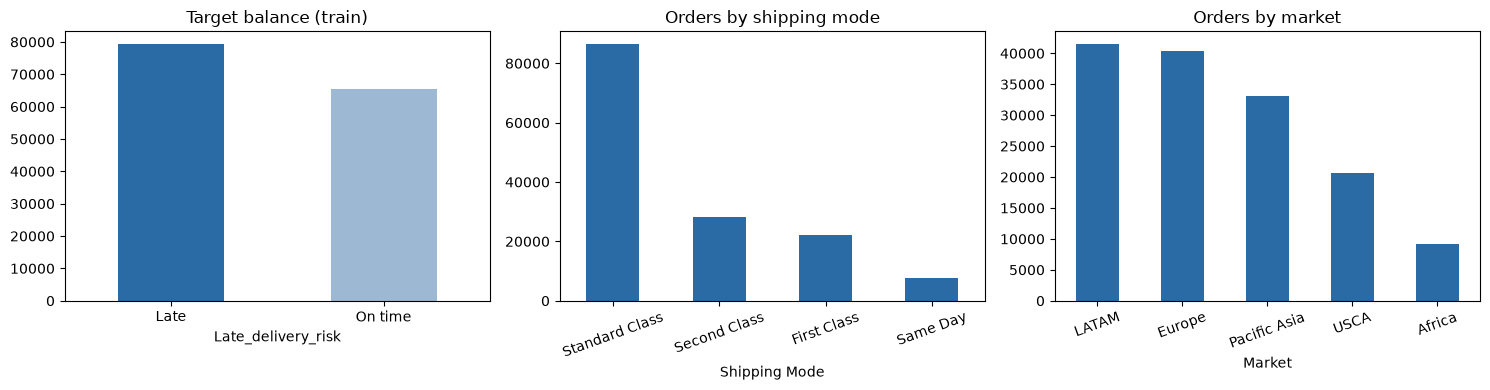

In [11]:
eda = X_train.copy()
eda["late"] = y_train
numeric_eda = X_train.select_dtypes(include="number").columns.tolist()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
y_train.map({0: "On time", 1: "Late"}).value_counts().plot(kind="bar", ax=axes[0], color=["#2A6AA5", "#9DB8D2"])
axes[0].set_title("Target balance (train)")
axes[0].tick_params(axis="x", rotation=0)
X_train["Shipping Mode"].value_counts().plot(kind="bar", ax=axes[1], color="#2A6AA5")
axes[1].set_title("Orders by shipping mode")
axes[1].tick_params(axis="x", rotation=20)
X_train["Market"].value_counts().plot(kind="bar", ax=axes[2], color="#2A6AA5")
axes[2].set_title("Orders by market")
axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

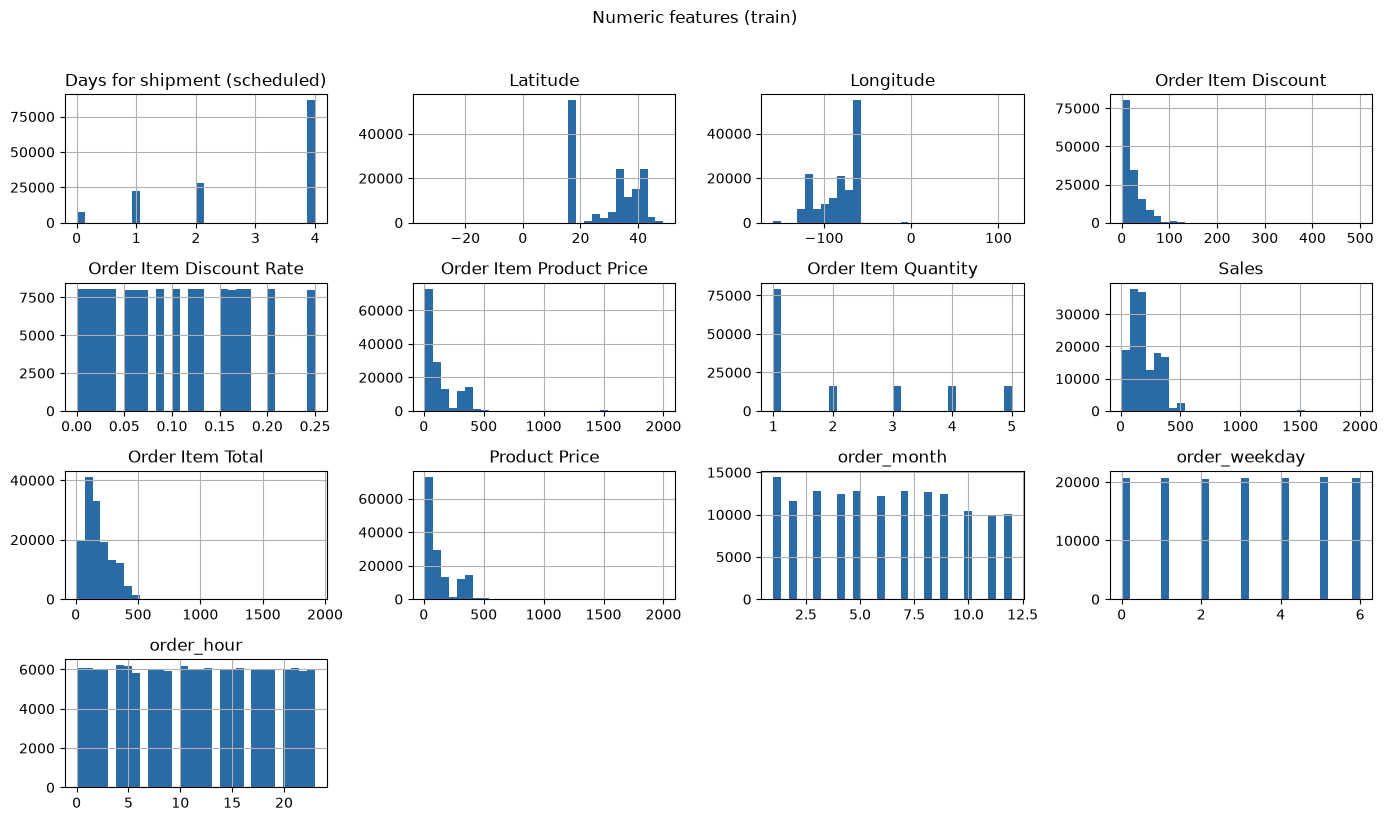

In [12]:
X_train[numeric_eda].hist(bins=30, figsize=(14, 8), color="#2A6AA5")
plt.suptitle("Numeric features (train)", y=1.02)
plt.tight_layout()
plt.show()

### 7.2 Bivariate analysis

How the late rate changes across the features. Each table shows the late rate (`mean`) and the number of rows it is based on (`count`).

In [13]:
for col in ["Shipping Mode", "Days for shipment (scheduled)", "Market", "Type", "Customer Segment"]:
    print(eda.groupby(col)["late"].agg(["mean", "count"]).round(3), "\n")

                 mean  count
Shipping Mode               
First Class     0.953  22229
Same Day        0.465   7767
Second Class    0.768  28202
Standard Class  0.380  86452 

                                mean  count
Days for shipment (scheduled)              
0                              0.465   7767
1                              0.953  22229
2                              0.768  28202
4                              0.380  86452 

               mean  count
Market                    
Africa        0.546   9175
Europe        0.552  40338
LATAM         0.539  41480
Pacific Asia  0.554  33021
USCA          0.552  20636 

           mean  count
Type                  
CASH      0.572  15681
DEBIT     0.570  55405
PAYMENT   0.573  33768
TRANSFER  0.487  39796 

                   mean  count
Customer Segment              
Consumer          0.547  74630
Corporate         0.547  44193
Home Office       0.553  25827 



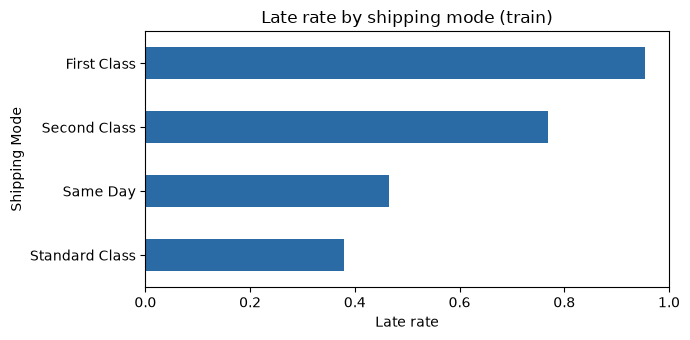

In [14]:
eda.groupby("Shipping Mode")["late"].mean().sort_values().plot(kind="barh", color="#2A6AA5", figsize=(7, 3.5))
plt.xlim(0, 1)
plt.xlabel("Late rate")
plt.title("Late rate by shipping mode (train)")
plt.tight_layout()
plt.show()

**Why are the faster modes late so often?** A hypothesis: the faster modes promise delivery times that the carriers do not actually deliver. The table below compares the promised days with the average **actual** days per mode. The actual days are used here for understanding the data only and never as a model feature.

In [15]:
promised_vs_actual = pd.DataFrame({
    "mode": X_train["Shipping Mode"],
    "promised days": df.loc[X_train.index, "Days for shipment (scheduled)"],
    "actual days": df.loc[X_train.index, "Days for shipping (real)"],
}).groupby("mode")[["promised days", "actual days"]].mean().round(2)
promised_vs_actual

,promised days,actual days
mode,,
First Class,1.0,2.00
Same Day,0.0,0.49
Second Class,2.0,3.99
Standard Class,4.0,3.99


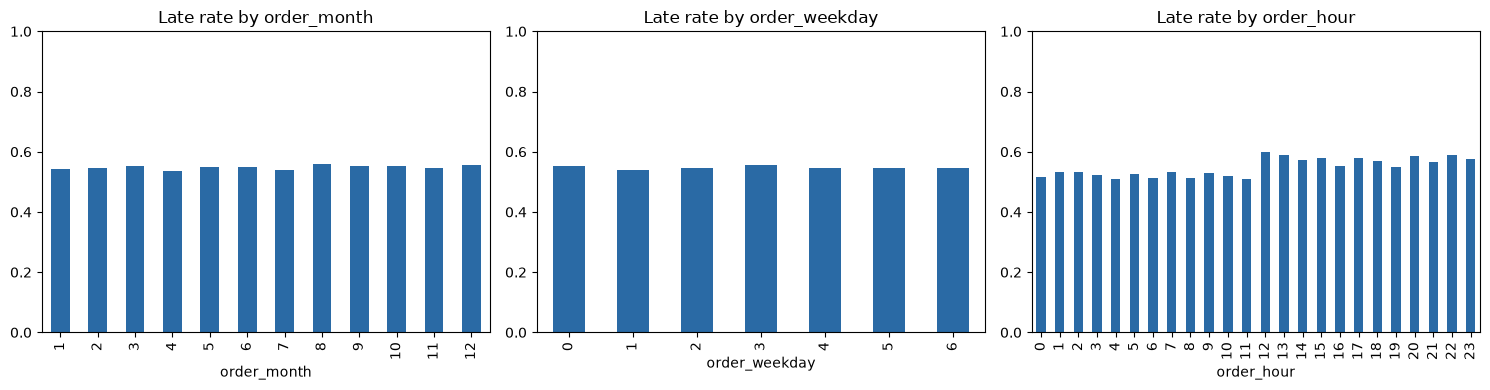

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["order_month", "order_weekday", "order_hour"]):
    eda.groupby(col)["late"].mean().plot(kind="bar", ax=ax, color="#2A6AA5")
    ax.set_title(f"Late rate by {col}")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

### 7.3 Multivariate analysis

Late rate across **combinations** of features, and the correlation between the numeric features and the target.

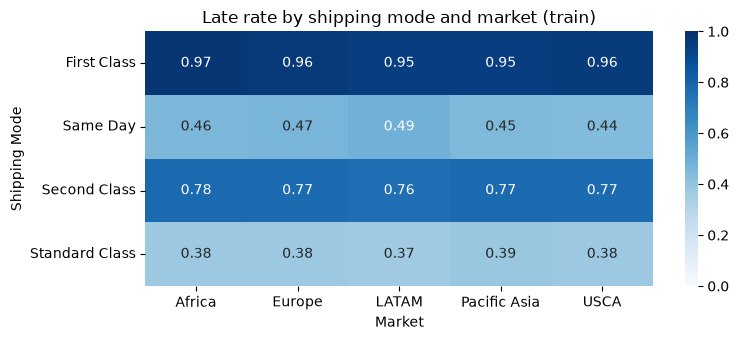

In [17]:
pivot = eda.pivot_table(values="late", index="Shipping Mode", columns="Market", aggfunc="mean")
plt.figure(figsize=(8, 3.5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Late rate by shipping mode and market (train)")
plt.tight_layout()
plt.show()

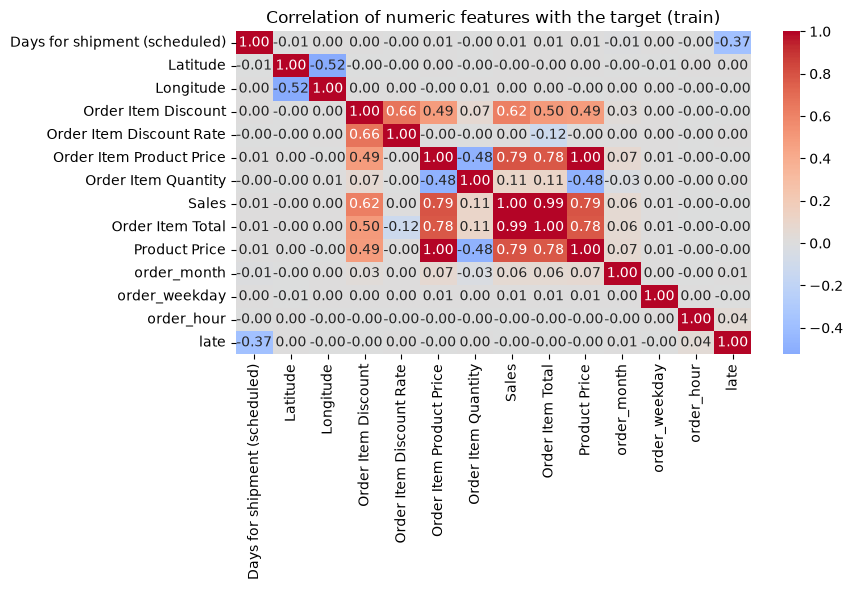

Days for shipment (scheduled)   -0.372
Order Item Total                -0.005
Sales                           -0.004
Order Item Product Price        -0.004
Product Price                   -0.004
Order Item Discount             -0.002
order_weekday                   -0.001
Longitude                       -0.001
Order Item Quantity              0.001
Order Item Discount Rate         0.001
Latitude                         0.001
order_month                      0.006
order_hour                       0.045


In [18]:
plt.figure(figsize=(9, 6))
sns.heatmap(eda[numeric_eda + ["late"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric features with the target (train)")
plt.tight_layout()
plt.show()

print(eda[numeric_eda + ["late"]].corr()["late"].drop("late").sort_values().round(3).to_string())

### 7.4 A simple rule as a yardstick

A rule that uses **only the shipping mode** (predict late for modes whose training late rate is above 50%) shows how much any model must add on top of the single strongest feature.

In [19]:
mode_rate = eda.groupby("Shipping Mode")["late"].mean()
mode_rule = (X_train["Shipping Mode"].map(mode_rate) > 0.5).astype(int)
print("Shipping-mode-only rule (train): accuracy = %.3f" % (mode_rule == y_train).mean())
print(classification_report(y_train, mode_rule, digits=3))

Shipping-mode-only rule (train): accuracy = 0.696
              precision    recall  f1-score   support

           0      0.613     0.884     0.724     65342
           1      0.850     0.540     0.661     79308

    accuracy                          0.696    144650
   macro avg      0.731     0.712     0.692    144650
weighted avg      0.743     0.696     0.689    144650



### 7.5 EDA insights (training set only)

1. **Shipping mode is by far the strongest signal.** The late rate is 95.3% for First Class, 76.8% for Second Class, 46.5% for Same Day and 38.0% for Standard Class. The scheduled days map one-to-one to the mode, so only one of them is needed.
2. **Faster modes are late mostly because of unrealistic promises.** Average actual shipping time is 2.0 days for First Class (promised 1), about 4 days for Second Class (promised 2) and about 4 days for Standard Class (promised 4). Second Class is no faster than Standard in practice. *(Hypothesis from averages.)*
3. **Market, customer segment, month and weekday carry almost no signal.** Late rates stay between about 0.54 and 0.56 across their values, and every numeric feature has a correlation with the target below 0.05.
4. **Order hour has a small effect:** orders placed after noon are slightly more often late.
5. **A rule using only the shipping mode is already a strong baseline:** 0.696 accuracy, but only 0.54 recall for late orders. The models must improve recall without destroying precision.

## 8. Feature reduction

Decisions based on the training data: columns with too many categories, and columns that duplicate each other.

In [20]:
categorical_now = [c for c in X_train.columns if c not in X_train.select_dtypes(include="number").columns]
print("Number of categories per categorical column:")
print(X_train[categorical_now].nunique().sort_values(ascending=False).to_string())

Number of categories per categorical column:
Order City          3510
Order State         1074
Customer City        563
Order Country        160
Product Name         118
Category Name         50
Customer State        46
Order Region          23
Department Name       11
Market                 5
Type                   4
Shipping Mode          4
Customer Segment       3
Customer Country       2


In [21]:
print("Order Item Product Price identical to Product Price:",
      (X_train["Order Item Product Price"] == X_train["Product Price"]).mean())
print()
print(X_train[["Sales", "Order Item Total", "Order Item Product Price", "Product Price",
               "Order Item Discount"]].corr().round(2))
print()
print(pd.crosstab(X_train["Shipping Mode"], X_train["Days for shipment (scheduled)"]))

Order Item Product Price identical to Product Price: 1.0

                          Sales  Order Item Total  Order Item Product Price  \
Sales                      1.00              0.99                      0.79   
Order Item Total           0.99              1.00                      0.78   
Order Item Product Price   0.79              0.78                      1.00   
Product Price              0.79              0.78                      1.00   
Order Item Discount        0.62              0.50                      0.49   

                          Product Price  Order Item Discount  
Sales                              0.79                 0.62  
Order Item Total                   0.78                 0.50  
Order Item Product Price           1.00                 0.49  
Product Price                      1.00                 0.49  
Order Item Discount                0.49                 1.00  

Days for shipment (scheduled)     0      1      2      4
Shipping Mode                  

**Decisions**

| Columns | Decision | Reason |
|---|---|---|
| `Order Item Product Price` | Drop | Identical to `Product Price` |
| `Order Item Total` | Drop | Correlation of 0.99 with `Sales` |
| `Order City`, `Order State`, `Customer City` | Drop | Hundreds to thousands of categories add noise and training time; their information is covered by `Order Region`, `Order Country` and `Market` |
| `Days for shipment (scheduled)` | Drop | Maps one-to-one to `Shipping Mode` (Same Day = 0, First Class = 1, Second Class = 2, Standard Class = 4), so it duplicates it |

The remaining categorical columns are one-hot encoded inside the pipeline, with rare categories grouped together.

In [22]:
REDUNDANT_COLS = ["Order Item Product Price", "Order Item Total"]
GEO_COLS = ["Order City", "Order State", "Customer City"]
DUPLICATE_COLS = ["Days for shipment (scheduled)"]

X_train = X_train.drop(columns=REDUNDANT_COLS + GEO_COLS + DUPLICATE_COLS)
X_test = X_test.drop(columns=REDUNDANT_COLS + GEO_COLS + DUPLICATE_COLS)

print("Final feature tables:", X_train.shape, X_test.shape)
print(list(X_train.columns))

Final feature tables: (144650, 21) (35869, 21)
['Type', 'Category Name', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order Country', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Quantity', 'Sales', 'Order Region', 'Product Name', 'Product Price', 'Shipping Mode', 'order_month', 'order_weekday', 'order_hour']


## 9. Preprocessing pipelines

All preprocessing lives **inside scikit-learn pipelines**, so it is fitted on the training folds only and nothing leaks into the validation or test data.

- **Numeric columns:** missing values filled with the median (scaled for the linear model).
- **Categorical columns:** missing values filled with the most frequent value, then one-hot encoded; categories with fewer than 100 rows are grouped into one "infrequent" bucket.
- **Cross-validation** uses `StratifiedGroupKFold`, so every order stays in a single fold and both classes are balanced across folds.

In [23]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
print("Numeric:", num_cols)
print("Categorical:", cat_cols)

# For the linear model: scaled numeric columns, sparse one-hot encoding
preprocess_linear = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100))]), cat_cols),
])

# For the tree models: no scaling needed, dense one-hot encoding
preprocess_trees = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100,
                                           sparse_output=False))]), cat_cols),
])

# Benchmark that uses only the shipping mode
mode_only = ColumnTransformer([("cat", OneHotEncoder(), ["Shipping Mode"])])

cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
SCORING = ["accuracy", "precision", "recall", "f1", "roc_auc"]


def cv_scores(pipe):
    """Average cross-validation scores on the training set (folds grouped by order)."""
    res = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=cv, scoring=SCORING)
    return {m: round(float(res[f"test_{m}"].mean()), 3) for m in SCORING}

Numeric: ['Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Quantity', 'Sales', 'Product Price', 'order_month', 'order_weekday', 'order_hour']
Categorical: ['Type', 'Category Name', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order Country', 'Order Region', 'Product Name', 'Shipping Mode']


## 10. Model comparison (cross-validation)

A simple baseline plus a shipping-mode-only benchmark and three algorithms from the course: logistic regression, random forest and gradient boosting. All use default or lightly set parameters and are compared on the **training data only** with 3-fold grouped cross-validation. 

In [24]:
experiments = {
    "Majority baseline (always late)": Pipeline([("prep", preprocess_linear),
                                                 ("clf", DummyClassifier(strategy="most_frequent"))]),
    "Shipping Mode only (logistic regression)": Pipeline([("prep", mode_only),
                                                          ("clf", LogisticRegression(max_iter=1000))]),
    "Logistic regression (all features)": Pipeline([("prep", preprocess_linear),
                                                    ("clf", LogisticRegression(max_iter=1000))]),
    "Random forest": Pipeline([("prep", preprocess_trees),
                               ("clf", RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1,
                                                              random_state=RANDOM_STATE))]),
    "Gradient boosting": Pipeline([("prep", preprocess_trees),
                                   ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
}

cv_results = {}
for name, estimator in experiments.items():
    t0 = time.time()
    cv_results[name] = cv_scores(estimator)
    print(f"{name:45s} done in {time.time() - t0:5.1f}s")

pd.DataFrame(cv_results).T.sort_values("roc_auc")

Majority baseline (always late)               done in  24.1s
Shipping Mode only (logistic regression)      done in  10.0s
Logistic regression (all features)            done in  26.7s
Random forest                                 done in  84.7s
Gradient boosting                             done in  62.1s


,accuracy,precision,recall,f1,roc_auc
Majority baseline (always late),0.548,0.548,1.000,0.708,0.500
Shipping Mode only (logistic regression),0.696,0.850,0.540,0.661,0.729
Logistic regression (all features),0.702,0.826,0.578,0.680,0.740
Random forest,0.719,0.855,0.587,0.696,0.755
Gradient boosting,0.716,0.838,0.597,0.697,0.767


**Reading the table**
- The majority baseline reaches recall 1.0 only by flagging every order; its ROC-AUC of 0.5 shows it cannot tell late from on-time orders. This is why recall is always read together with precision and ROC-AUC.
- Using only the shipping mode already gives a ROC-AUC of about 0.73. The other columns add a small but consistent gain, and the tree models do slightly better than the linear model.
- Gradient boosting and the random forest are close, so both are tuned next.

## 11. Hyperparameter tuning

`RandomizedSearchCV` searches a limited set of settings on the **training data only**, using the same grouped folds and **ROC-AUC** as the score. ROC-AUC is used because recall depends on the cutoff, which is chosen separately in section 13.

- Gradient boosting: 6 random candidates from a small grid, tuned on the full training set.
- Random forest: 4 candidates, tuned on a 30% sample of the training **orders** to keep it fast (whole orders are sampled, so groups stay intact).

If `RUN_TUNING = False`, the searches are skipped and the best settings found by them are used directly.

In [25]:
hgb_pipe = Pipeline([("prep", preprocess_trees),
                     ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))])
rf_pipe = Pipeline([("prep", preprocess_trees),
                    ("clf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE))])

# Best settings found by the searches below (used when RUN_TUNING = False)
HGB_BEST = {"clf__learning_rate": 0.05, "clf__max_iter": 100,
            "clf__max_leaf_nodes": 15, "clf__min_samples_leaf": 20}
RF_BEST = {"clf__max_depth": 12, "clf__max_features": 0.3, "clf__min_samples_leaf": 20}

if RUN_TUNING:
    hgb_grid = {
        "clf__learning_rate": [0.05, 0.1, 0.2],
        "clf__max_iter": [100, 200],
        "clf__max_leaf_nodes": [15, 31],
        "clf__min_samples_leaf": [20, 100],
    }
    t0 = time.time()
    hgb_search = RandomizedSearchCV(hgb_pipe, hgb_grid, n_iter=6, scoring="roc_auc", cv=cv,
                                    random_state=RANDOM_STATE, n_jobs=1)
    hgb_search.fit(X_train, y_train, groups=groups_train)
    i = hgb_search.best_index_
    print(f"Gradient boosting search: {(time.time() - t0) / 60:.1f} min | best CV ROC-AUC "
          f"{hgb_search.best_score_:.3f} +/- {hgb_search.cv_results_['std_test_score'][i]:.3f}")
    print("  best settings:", hgb_search.best_params_)
    HGB_BEST = hgb_search.best_params_
else:
    print("Tuning skipped. Gradient boosting settings:", HGB_BEST)

Gradient boosting search: 4.5 min | best CV ROC-AUC 0.769 +/- 0.001
  best settings: {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 15, 'clf__max_iter': 100, 'clf__learning_rate': 0.05}


In [26]:
if RUN_TUNING:
    rf_grid = {
        "clf__max_depth": [8, 12],
        "clf__min_samples_leaf": [5, 20, 50],
        "clf__max_features": ["sqrt", 0.3],
    }
    # sample whole orders, not random rows, so every order stays in one fold
    sampled_orders = groups_train.drop_duplicates().sample(frac=0.3, random_state=RANDOM_STATE)
    mask = groups_train.isin(sampled_orders).values
    print("Rows in the tuning sample:", mask.sum())

    t0 = time.time()
    rf_search = RandomizedSearchCV(rf_pipe, rf_grid, n_iter=4, scoring="roc_auc", cv=cv,
                                   random_state=RANDOM_STATE, n_jobs=1)
    rf_search.fit(X_train[mask], y_train[mask], groups=groups_train[mask])
    j = rf_search.best_index_
    print(f"Random forest search: {(time.time() - t0) / 60:.1f} min | best CV ROC-AUC "
          f"{rf_search.best_score_:.3f} +/- {rf_search.cv_results_['std_test_score'][j]:.3f} (on the sample)")
    print("  best settings:", rf_search.best_params_)
    RF_BEST = rf_search.best_params_
else:
    print("Tuning skipped. Random forest settings:", RF_BEST)

Rows in the tuning sample: 43345
Random forest search: 1.2 min | best CV ROC-AUC 0.767 +/- 0.004 (on the sample)
  best settings: {'clf__min_samples_leaf': 20, 'clf__max_features': 0.3, 'clf__max_depth': 12}


**Both tuned models are scored on the full training set** with the same folds, so the comparison is fair.

In [27]:
hgb_tuned = clone(hgb_pipe).set_params(**HGB_BEST)
rf_tuned = clone(rf_pipe).set_params(**RF_BEST)

if RUN_TUNING:
    cv_results["Random forest (tuned)"] = cv_scores(rf_tuned)
    cv_results["Gradient boosting (tuned)"] = cv_scores(hgb_tuned)

pd.DataFrame(cv_results).T.sort_values("roc_auc")

,accuracy,precision,recall,f1,roc_auc
Majority baseline (always late),0.548,0.548,1.000,0.708,0.500
Shipping Mode only (logistic regression),0.696,0.850,0.540,0.661,0.729
Logistic regression (all features),0.702,0.826,0.578,0.680,0.740
Random forest,0.719,0.855,0.587,0.696,0.755
Gradient boosting,0.716,0.838,0.597,0.697,0.767
Gradient boosting (tuned),0.719,0.854,0.587,0.696,0.769
Random forest (tuned),0.719,0.854,0.587,0.696,0.770


**Result of tuning**
- Tuning added very little: the best gradient boosting settings are the gentlest in the grid (learning rate 0.05, 15 leaf nodes), so extra complexity does not help.
- The tuned random forest and the tuned gradient boosting model score the same (ROC-AUC about 0.77, differences of 0.001 are within the fold-to-fold noise). The search is limited (6 of 24 settings for boosting, 4 of 12 for the forest), so this is a "limited random search", not an exhaustive one.
- The models seem to hit a ceiling around 0.77 ROC-AUC. A likely reason is that the factors behind real delivery time (carrier, weather, distance) are not in this dataset.

## 12. Final model

**Gradient boosting** is chosen. Its performance is tied with the random forest, and it is the better practical choice: its fold-to-fold spread was very small in the search (about 0.001), it produces smooth probabilities (needed for the cutoff analysis in section 13), and its saved file stays small, which matters for deployment.

In [28]:
final_model = clone(hgb_tuned)
final_model.fit(X_train, y_train)
print("Final model fitted on", len(X_train), "training rows.")
final_model

Final model fitted on 144650 training rows.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Type','Category Name','Customer Country',...,'order_month', 'order_weekday','order_hour']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthroug

## 13. Choosing the decision cutoff (training data only)

A model outputs a probability, and someone must decide above which probability an order is flagged as late. That choice is made here **without touching the test set**, using out-of-fold predictions: every training order is scored by a model that never saw it.

In [29]:
oof_proba = cross_val_predict(clone(final_model), X_train, y_train, groups=groups_train, cv=cv,
                              method="predict_proba")[:, 1]
print("Predicted probabilities, percentiles 0/5/25/50/75/95/100:")
print(np.percentile(oof_proba, [0, 5, 25, 50, 75, 95, 100]).round(3))

Predicted probabilities, percentiles 0/5/25/50/75/95/100:
[0.029 0.329 0.384 0.401 0.787 0.995 0.996]


**Operating points:** what happens at different cutoffs.

In [30]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    pred_t = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred_t).ravel()
    rows.append({"cutoff": t, "orders flagged (%)": round(pred_t.mean() * 100, 1),
                 "precision": round(tp / (tp + fp), 3) if (tp + fp) else np.nan,
                 "recall": round(tp / (tp + fn), 3), "false alarms": fp, "missed late": fn})
pd.DataFrame(rows)

,cutoff,orders flagged (%),precision,recall,false alarms,missed late
0,0.3,96.6,0.565,0.996,60790,314
1,0.4,51.7,0.727,0.686,20406,24878
2,0.5,37.7,0.854,0.587,7940,32744
3,0.6,37.5,0.857,0.586,7769,32859
4,0.7,34.0,0.873,0.541,6267,36368
5,0.8,19.9,0.939,0.341,1756,52283


**Cost-based cutoff.** The real cost of a missed late order versus a false alarm is unknown, so it is treated as a **business assumption**: a false alarm costs 1, a missed late order costs `c`, and several values of `c` are tested. An order is worth flagging when its probability is above `1 / (1 + c)`.

In [31]:
sweep = []
for t in np.arange(0.20, 0.91, 0.01):
    pred_t = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred_t).ravel()
    sweep.append({"cutoff": round(t, 2), "FP": fp, "FN": fn,
                  "precision": tp / (tp + fp) if (tp + fp) else np.nan, "recall": tp / (tp + fn)})
sweep = pd.DataFrame(sweep)

n_late, n_ontime = int(y_train.sum()), int((y_train == 0).sum())
for c in [1, 2, 3, 5]:
    cost = sweep["FP"] + c * sweep["FN"]
    best = sweep.loc[cost.idxmin()]
    print(f"c = {c}: best cutoff {best['cutoff']:.2f} | total cost {int(cost.min()):,} | "
          f"recall {best['recall']:.2f}, precision {best['precision']:.2f} | "
          f"cost if every order is flagged: {n_ontime:,} | if none: {c * n_late:,}")

c = 1: best cutoff 0.61 | total cost 40,624 | recall 0.59, precision 0.86 | cost if every order is flagged: 65,342 | if none: 79,308
c = 2: best cutoff 0.20 | total cost 61,351 | recall 1.00, precision 0.56 | cost if every order is flagged: 65,342 | if none: 158,616
c = 3: best cutoff 0.20 | total cost 61,356 | recall 1.00, precision 0.56 | cost if every order is flagged: 65,342 | if none: 237,924
c = 5: best cutoff 0.20 | total cost 61,366 | recall 1.00, precision 0.56 | cost if every order is flagged: 65,342 | if none: 396,540


**The riskiest orders.** A logistics team usually cannot act on every order, only on the riskiest slice.

In [32]:
sorted_outcomes = y_train.values[np.argsort(-oof_proba)]
for k in [0.10, 0.20, 0.30, 0.50]:
    n = int(len(sorted_outcomes) * k)
    print(f"Top {int(k * 100)}% riskiest: {sorted_outcomes[:n].mean():.3f} are late | "
          f"captures {sorted_outcomes[:n].sum() / sorted_outcomes.sum():.1%} of all late orders")

Top 10% riskiest: 1.000 are late | captures 18.2% of all late orders
Top 20% riskiest: 0.939 are late | captures 34.2% of all late orders
Top 30% riskiest: 0.892 are late | captures 48.8% of all late orders
Top 50% riskiest: 0.739 are late | captures 67.4% of all late orders


In [33]:
TIER_BINS = [0, 0.50, 0.80, 1.0001]
TIER_LABELS = ["Lower (<0.50)", "High (0.50-0.80)", "Very high (>=0.80)"]

tiers_train = pd.cut(oof_proba, bins=TIER_BINS, labels=TIER_LABELS, right=False)
pd.DataFrame({"tier": tiers_train, "late": y_train.values}).groupby("tier", observed=True)["late"] \
    .agg(["mean", "count"]).round(3)

,mean,count
tier,,
Lower (<0.50),0.363,90146
High (0.50-0.80),0.760,25723
Very high (>=0.80),0.939,28781


**Findings and decision**
- If a missed late order costs about the same as a false alarm (`c = 1`), the best cutoff is about 0.5 to 0.61 (precision about 0.86, recall about 0.59). The two cutoffs behave almost identically, because the model's probabilities cluster by shipping mode.
- If a missed late order costs twice as much or more (`c >= 2`), the cheapest policy is to flag nearly every order. Even the lowest-risk group is about 36% late, so per-order prediction adds little when warnings are cheap. The model is most valuable for **prioritization**, when only some orders can be acted on.
- The riskiest 10% of orders were 100% late, and the riskiest 30% were about 89% late (overall rate: 54.8%).
- **Chosen cutoff: 0.50** ("more likely late than not"), the simplest to explain, with the same outcome as 0.61.
- The three risk tiers separate the late rates cleanly (about 36%, 76% and 94%), so the app shows a tier together with the historical late rate of similar orders.

In [34]:
CUTOFF = 0.50

## 14. Final evaluation on the test set

This is the **only time** the test set is used. No setting is changed after seeing these numbers.

In [35]:
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= CUTOFF).astype(int)

mode_benchmark = Pipeline([("prep", mode_only), ("clf", LogisticRegression(max_iter=1000))])
mode_benchmark.fit(X_train, y_train)


def score_row(y_true, y_pred, y_score):
    return {"accuracy": accuracy_score(y_true, y_pred), "precision": precision_score(y_true, y_pred),
            "recall": recall_score(y_true, y_pred), "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_score)}


test_results = pd.DataFrame({
    "Majority baseline (always late)": score_row(y_test, np.ones(len(y_test), dtype=int),
                                                 np.full(len(y_test), 0.5)),
    "Shipping Mode only (logistic regression)": score_row(y_test, mode_benchmark.predict(X_test),
                                                          mode_benchmark.predict_proba(X_test)[:, 1]),
    "Gradient boosting (final)": score_row(y_test, pred_test, proba_test),
}).T.round(3)
test_results

,accuracy,precision,recall,f1,roc_auc
Majority baseline (always late),0.548,0.548,1.000,0.708,0.500
Shipping Mode only (logistic regression),0.694,0.845,0.541,0.660,0.725
Gradient boosting (final),0.716,0.850,0.585,0.693,0.770


              precision    recall  f1-score   support

     On time      0.634     0.875     0.736     16200
        Late      0.850     0.585     0.693     19669

    accuracy                          0.716     35869
   macro avg      0.742     0.730     0.714     35869
weighted avg      0.753     0.716     0.712     35869

ROC-AUC: 0.77


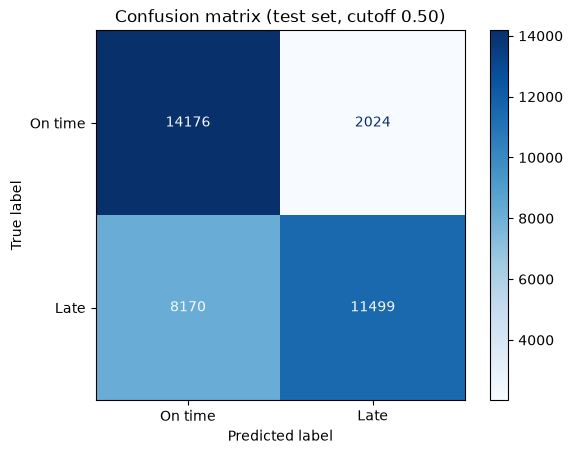

In [36]:
print(classification_report(y_test, pred_test, target_names=["On time", "Late"], digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, proba_test), 3))

ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["On time", "Late"], cmap="Blues")
plt.title("Confusion matrix (test set, cutoff %.2f)" % CUTOFF)
plt.show()

**Risk tiers and the riskiest orders on the test set.**

In [37]:
tiers_test = pd.cut(proba_test, bins=TIER_BINS, labels=TIER_LABELS, right=False)
print(pd.DataFrame({"tier": tiers_test, "late": y_test.values}).groupby("tier", observed=True)["late"]
      .agg(["mean", "count"]).round(3), "\n")

sorted_test = y_test.values[np.argsort(-proba_test)]
for k in [0.10, 0.20, 0.30]:
    n = int(len(sorted_test) * k)
    print(f"Top {int(k * 100)}% riskiest: {sorted_test[:n].mean():.3f} are late | "
          f"captures {sorted_test[:n].sum() / sorted_test.sum():.1%} of all late orders")

                     mean  count
tier                            
Lower (<0.50)       0.366  22346
High (0.50-0.80)    0.745   6047
Very high (>=0.80)  0.936   7476 

Top 10% riskiest: 1.000 are late | captures 18.2% of all late orders
Top 20% riskiest: 0.940 are late | captures 34.3% of all late orders
Top 30% riskiest: 0.892 are late | captures 48.8% of all late orders


### Error analysis

Where does the model go wrong? Results by shipping mode (`flagged` is the share of orders the model flags as late, `missed_late` the number of late orders it did not flag).

In [38]:
errors = X_test.copy()
errors["late"] = y_test.values
errors["flagged"] = pred_test
errors["missed_late"] = (errors["late"] == 1) & (errors["flagged"] == 0)

errors.groupby("Shipping Mode").agg(orders=("late", "size"), late_rate=("late", "mean"),
                                    flagged=("flagged", "mean"), missed_late=("missed_late", "sum")).round(3)

,orders,late_rate,flagged,missed_late
Shipping Mode,,,,
First Class,5585,0.953,1.000,0
Same Day,1970,0.428,0.450,0
Second Class,7014,0.759,1.000,0
Standard Class,21300,0.384,0.002,8170


**Interpretation**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Majority baseline (always late) | 0.548 | 0.548 | 1.000 | 0.708 | 0.500 |
| Shipping Mode only (logistic regression) | 0.694 | 0.845 | 0.541 | 0.660 | 0.725 |
| **Gradient boosting (final, cutoff 0.50)** | **0.716** | **0.850** | **0.585** | **0.693** | **0.770** |

- The test scores match the cross-validation scores (ROC-AUC 0.770 vs 0.769), so the model generalizes and the split by order kept the evaluation honest.
- When the model flags an order as late, it is right 85% of the time. It catches 58.5% of late orders: 11,499 caught, 8,170 missed, and 2,024 false alarms.
- **All missed late orders are Standard Class.** That mode is 38% late, but the model flags only 0.2% of its orders, because nothing in the data separates the late Standard Class orders from the on-time ones.
- First Class and Second Class are flagged almost every time. This is right for First Class (95% late) and produces most of the false alarms in Second Class (76% late).
- The risk tiers hold up on unseen data: about 37% late in the lower tier, 75% in the high tier and 94% in the very high tier. The riskiest 10% of orders were 100% late.
- An honest 0.77 ROC-AUC is much lower than the roughly 97% that a model using the leaked columns would report.

## 15. Business insight and limitations

### What it means for the company
1. **Fix the promises first.** First Class (95% late) and Second Class (about 77% late) miss their promised delivery times far more often than Standard Class, and Second Class is no faster than Standard in practice (hypothesis from averages). The company should review whether those promises are achievable, or quote a longer delivery window.
2. **Warn customers on flagged orders.** Orders in the high and very high tiers were late about 75% and 94% of the time.
3. **Use the model to prioritize.** When the team can act on only part of the orders, start with the riskiest 10 to 30%.
4. **Do not rely on it for Standard Class.** All missed late orders are Standard Class, so a human check or extra data is needed there.
5. **Upgrading the shipping mode is not a fix.** In this data, the faster modes have *higher* late rates, so the advice to upgrade does not follow from the evidence.

### Limitations
- The data has no carrier, weather, distance or warehouse information, so even the lowest-risk tier is about 37% late.
- The overall late rate (about 55%) is nearly the same across markets, customer segments, months and weekdays, and the labels could not be checked against source records. Results apply to this dataset and may not transfer to another company.
- The label comes from after-the-fact information (actual vs. scheduled days), and canceled shipments are labelled "not late" (4,423 rows took longer than scheduled but are labelled not late). Cancellation cannot be known at order time, so these rows act as label noise.
- The hyperparameter search was limited, and the cost ratio used for the cutoff is a business assumption rather than a measured value.
- The model uses one company's data from a single time period.

## 16. Saving the model for the app

The Streamlit app needs more than the model: the list of columns, default values for the columns the user does not fill in, and lookup tables so that a chosen product or country fills in its category, department, region and market consistently. Everything is saved in one file.

In [39]:
def most_common(s):
    return s.mode().iloc[0]


products = X_train.groupby("Product Name").agg(**{
    "Category Name": ("Category Name", most_common),
    "Department Name": ("Department Name", most_common),
    "Product Price": ("Product Price", "median"),
    "Sales": ("Sales", "median"),
})
countries = X_train.groupby("Order Country").agg(**{
    "Order Region": ("Order Region", most_common),
    "Market": ("Market", most_common),
})
defaults = {c: (X_train[c].median() if c in num_cols else most_common(X_train[c])) for c in X_train.columns}

bundle = {
    "model": final_model,
    "columns": list(X_train.columns),
    "defaults": defaults,
    "products": products,
    "countries": countries,
    "options": {c: sorted(X_train[c].unique()) for c in ["Shipping Mode", "Type", "Customer Segment"]},
}
joblib.dump(bundle, "model.joblib", compress=3)
print("Saved model.joblib | size: %.1f MB" % (os.path.getsize("model.joblib") / 1e6))

Saved model.joblib | size: 0.1 MB


## Next step

Run the web app from a terminal in the project folder:

```
streamlit run app.py
```